In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, silhouette_score
)

In [3]:
# Regression comparison
diabetes = load_diabetes()
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.2, random_state=42
)
reg_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000))
}
reg_rows = []
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred)
    })
reg_comparison = pd.DataFrame(reg_rows).sort_values("RMSE")
print("Regression comparison (lower MAE/RMSE and higher R2 are generally preferred):")
display(reg_comparison.round(3))

Regression comparison (lower MAE/RMSE and higher R2 are generally preferred):


,Model,MAE,RMSE,R2
2,Lasso,42.805,53.709,0.456
1,Ridge,42.812,53.777,0.454
0,Linear Regression,42.794,53.853,0.453


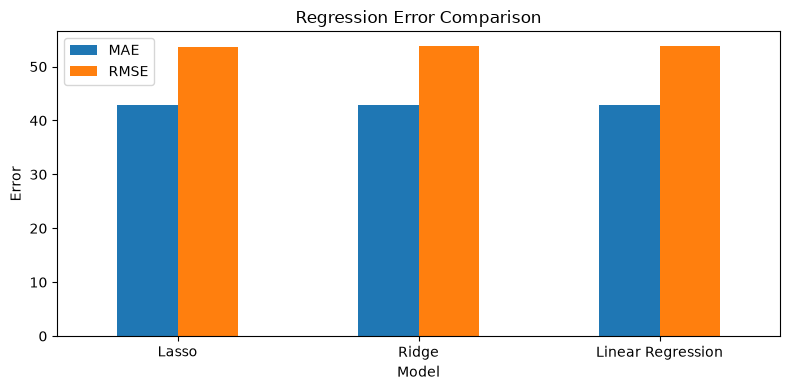

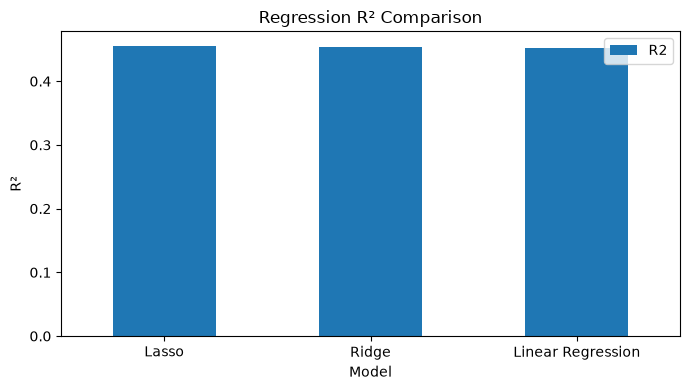

In [4]:
# Graph: regression metrics
reg_comparison.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Regression Error Comparison")
plt.ylabel("Error")
plt.tight_layout()
plt.show()

reg_comparison.set_index("Model")[["R2"]].plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Regression R² Comparison")
plt.ylabel("R²")
plt.tight_layout()
plt.show()

In [5]:
# Classification comparison on one shared breast-cancer test split
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)
class_models = {
    "Logistic L2": make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", max_iter=10000)),
    "Logistic L1": make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", max_iter=10000)),
    "Naive Bayes": GaussianNB(),
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
class_rows = []
for name, model in class_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    class_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })
class_comparison = pd.DataFrame(class_rows).sort_values("F1", ascending=False)
print("Classification comparison (higher scores are generally preferred):")
display(class_comparison.round(3))

c:\Users\samik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\samik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Classification comparison (higher scores are generally preferred):


,Model,Accuracy,Precision,Recall,F1
1,Logistic L1,0.991,0.986,1.000,0.993
0,Logistic L2,0.982,0.986,0.986,0.986
5,Gradient Boosting,0.956,0.947,0.986,0.966
4,Random Forest,0.956,0.959,0.972,0.966
3,Bagging,0.939,0.945,0.958,0.952
2,Naive Bayes,0.939,0.945,0.958,0.952


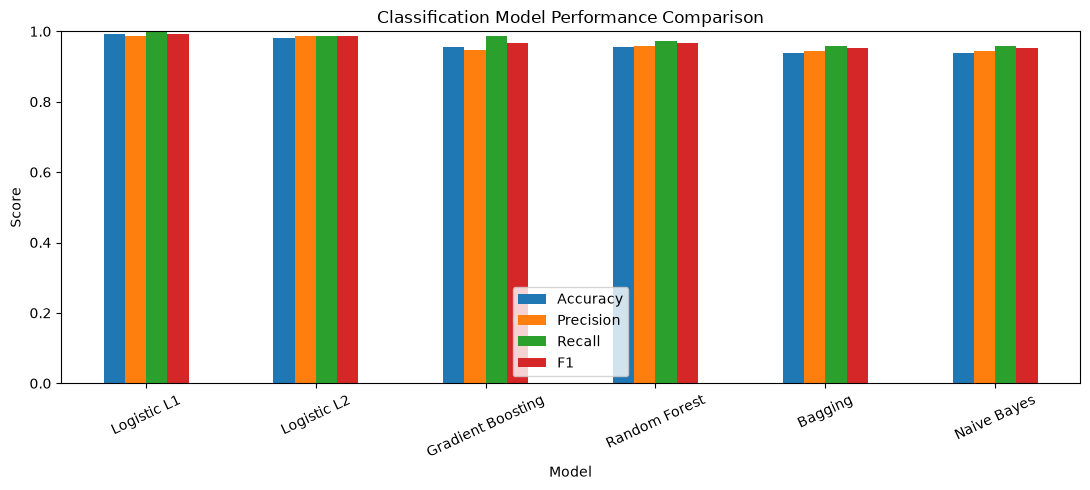

In [6]:
# Graph: classification metrics
class_comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=25
)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

In [7]:
# Clustering comparison on the same generated dataset
X_cluster, _ = make_blobs(n_samples=250, centers=3, cluster_std=1.1, random_state=42)
cluster_models = {
    "K-means": KMeans(n_clusters=3, random_state=42, n_init=10),
    "Hierarchical Ward": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "GMM": GaussianMixture(n_components=3, random_state=42)
}
cluster_rows = []
cluster_labels = {}
for name, model in cluster_models.items():
    labels = model.fit_predict(X_cluster)
    cluster_labels[name] = labels
    cluster_rows.append({"Model": name, "Silhouette": silhouette_score(X_cluster, labels)})
cluster_comparison = pd.DataFrame(cluster_rows).sort_values("Silhouette", ascending=False)
print("Clustering comparison (higher silhouette score generally means better-separated clusters):")
display(cluster_comparison.round(3))

Clustering comparison (higher silhouette score generally means better-separated clusters):


,Model,Silhouette
0,K-means,0.831
1,Hierarchical Ward,0.831
2,GMM,0.831


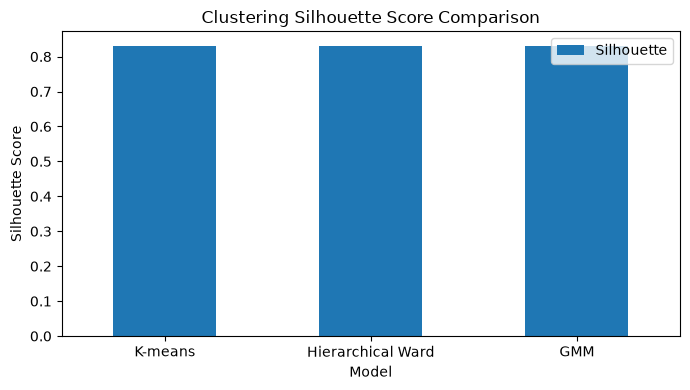

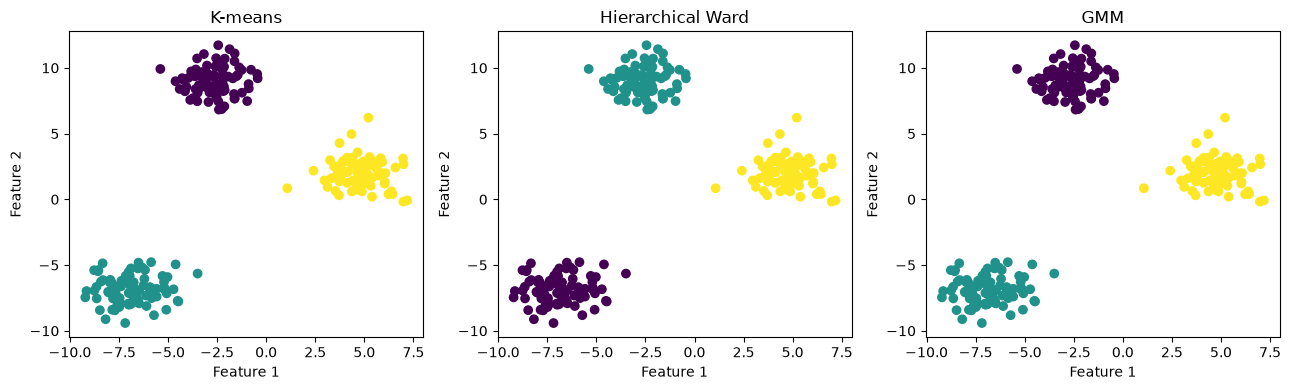

In [8]:
# Graph: clustering scores and cluster plots
cluster_comparison.set_index("Model")[["Silhouette"]].plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Clustering Silhouette Score Comparison")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, labels) in zip(axes, cluster_labels.items()):
    ax.scatter(X_cluster[:, 0], X_cluster[:, 1], c=labels)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()